# 4. EDA with Data Visualization
Charts that explain which factors relate to landing success. Save a screenshot of each for the report.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv')
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


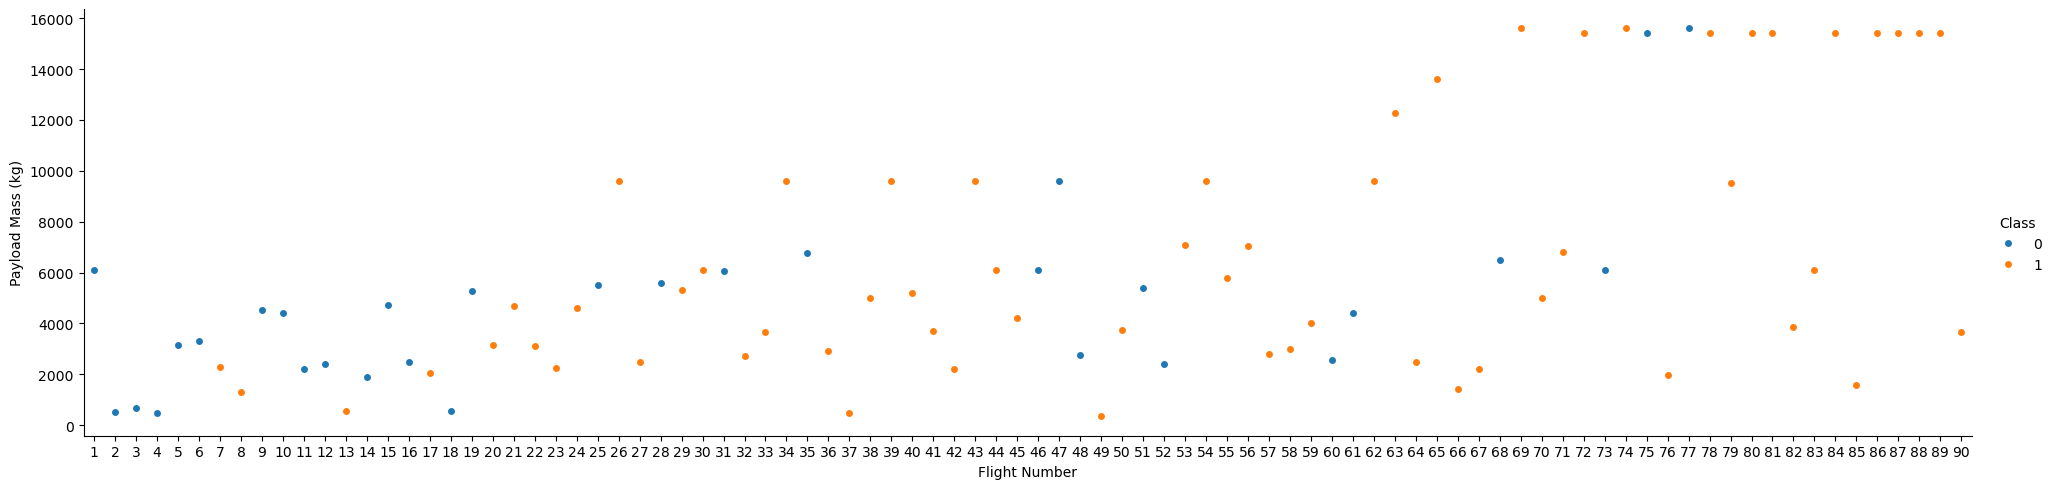

In [2]:
# Flight number vs payload mass, coloured by landing class
sns.catplot(y='PayloadMass', x='FlightNumber', hue='Class', data=df, aspect=4)
plt.xlabel('Flight Number'); plt.ylabel('Payload Mass (kg)')
plt.show()

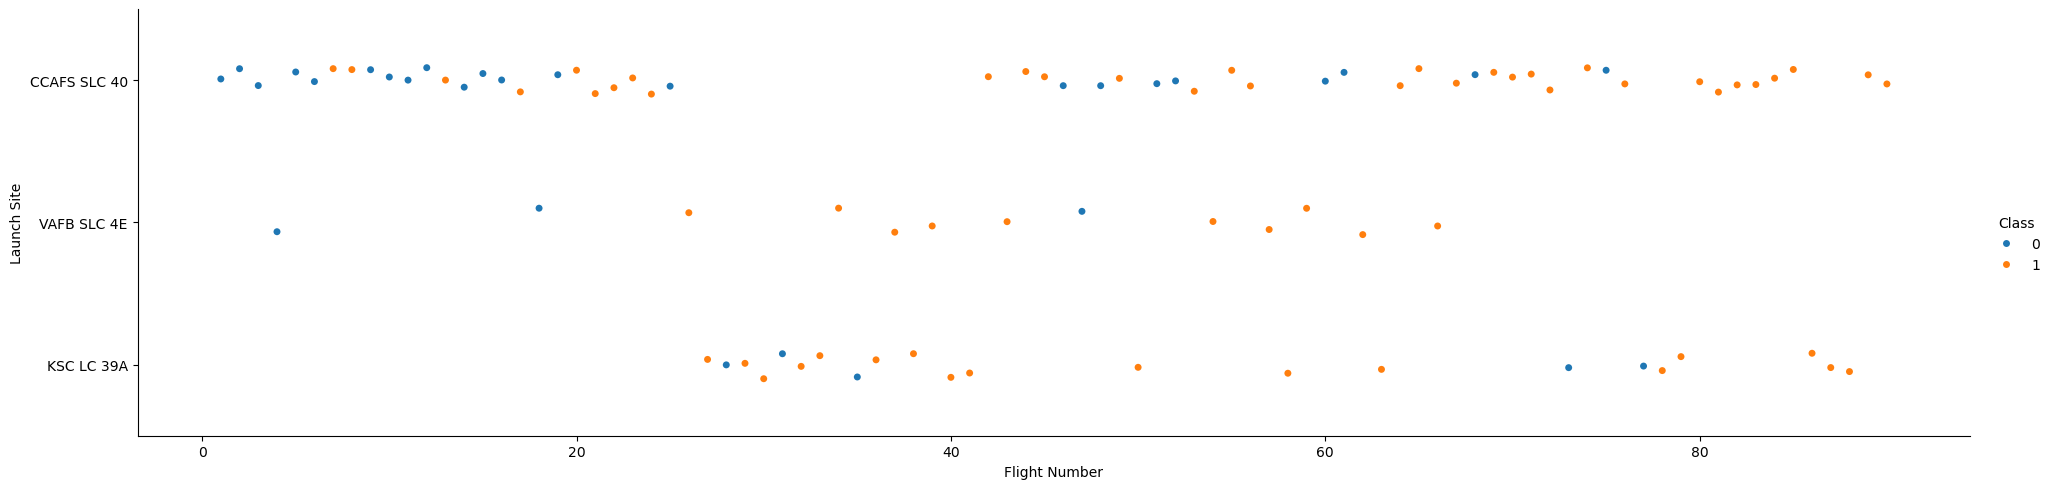

In [3]:
# Flight number vs launch site
sns.catplot(y='LaunchSite', x='FlightNumber', hue='Class', data=df, aspect=4)
plt.xlabel('Flight Number'); plt.ylabel('Launch Site')
plt.show()

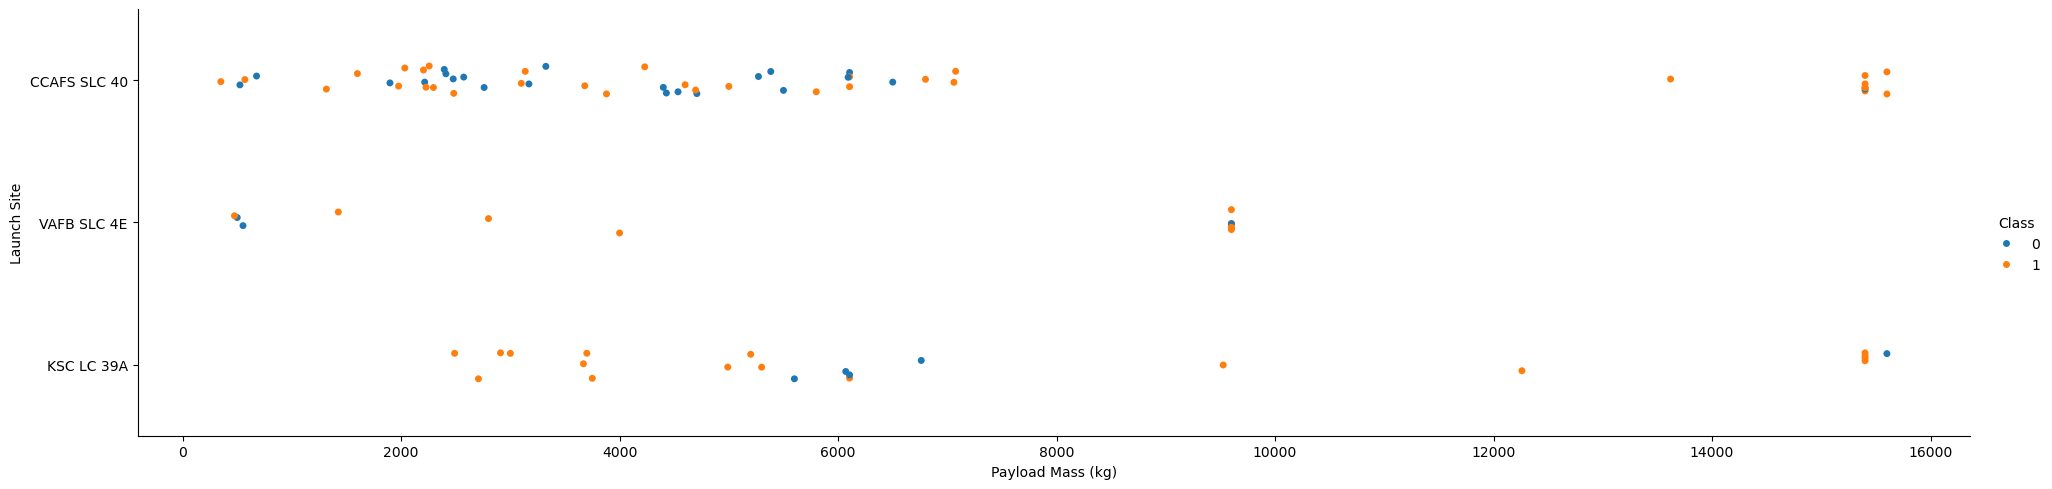

In [4]:
# Payload mass vs launch site
sns.catplot(y='LaunchSite', x='PayloadMass', hue='Class', data=df, aspect=4)
plt.xlabel('Payload Mass (kg)'); plt.ylabel('Launch Site')
plt.show()

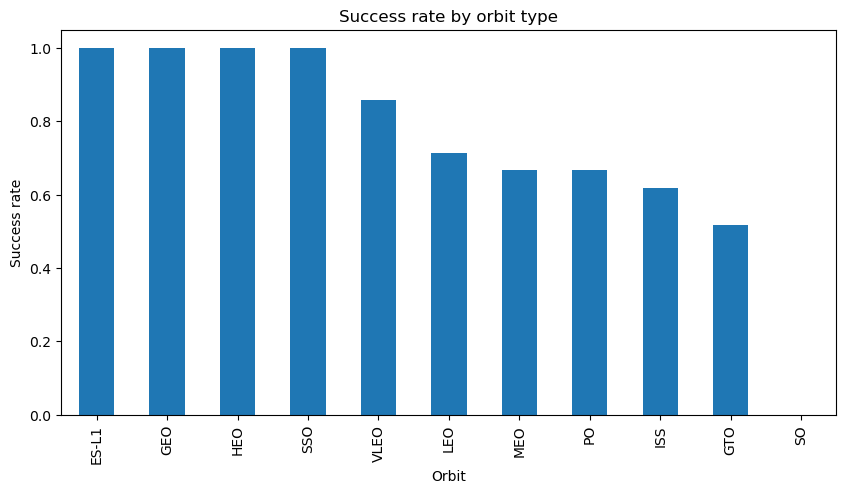

Orbit
ES-L1    1.000000
GEO      1.000000
HEO      1.000000
SSO      1.000000
VLEO     0.857143
LEO      0.714286
MEO      0.666667
PO       0.666667
ISS      0.619048
GTO      0.518519
SO       0.000000
Name: Class, dtype: float64

In [5]:
# Success rate of each orbit
orbit_success = df.groupby('Orbit')['Class'].mean().sort_values(ascending=False)
orbit_success.plot(kind='bar', figsize=(10, 5), color='tab:blue')
plt.ylabel('Success rate'); plt.title('Success rate by orbit type')
plt.show()
orbit_success

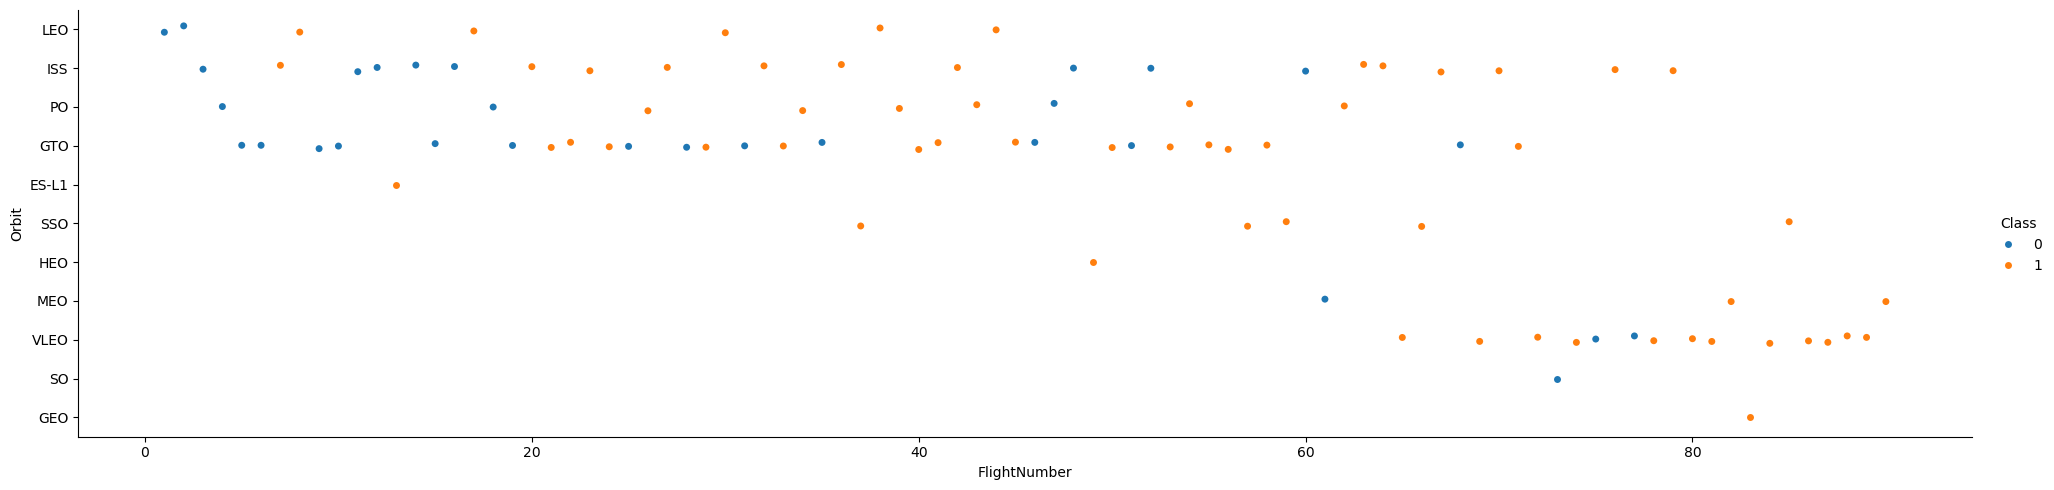

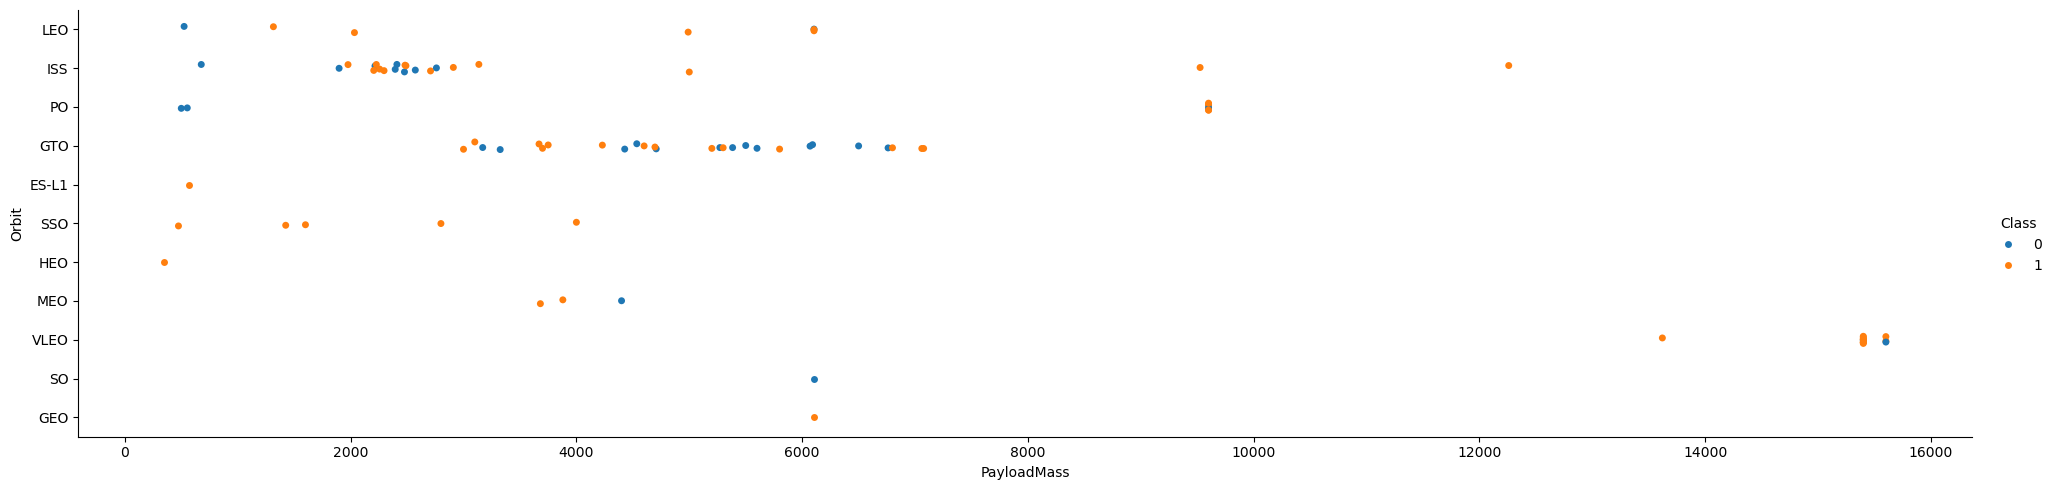

In [6]:
# Flight number vs orbit and payload vs orbit
sns.catplot(y='Orbit', x='FlightNumber', hue='Class', data=df, aspect=4)
plt.show()
sns.catplot(y='Orbit', x='PayloadMass', hue='Class', data=df, aspect=4)
plt.show()

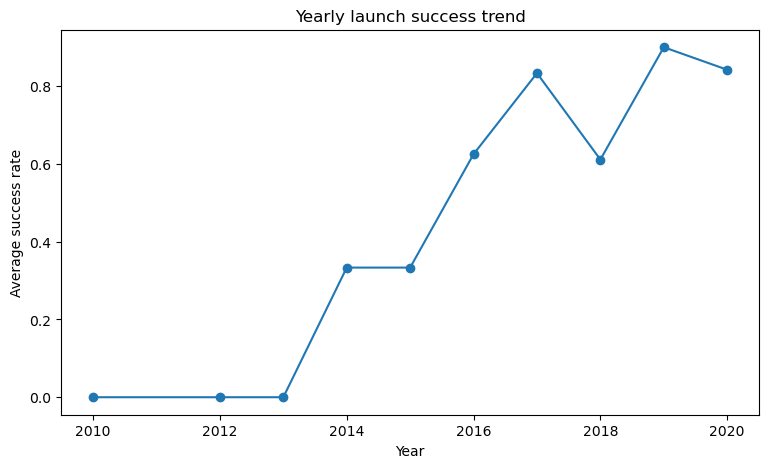

Year
2010    0.000000
2012    0.000000
2013    0.000000
2014    0.333333
2015    0.333333
2016    0.625000
2017    0.833333
2018    0.611111
2019    0.900000
2020    0.842105
Name: Class, dtype: float64

In [7]:
# Yearly success trend
df['Year'] = pd.to_datetime(df['Date']).dt.year
yearly = df.groupby('Year')['Class'].mean()
yearly.plot(kind='line', marker='o', figsize=(9, 5))
plt.xlabel('Year'); plt.ylabel('Average success rate'); plt.title('Yearly launch success trend')
plt.show()
yearly

In [8]:
# One-hot encode the categorical features for modelling
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins',
               'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
features_one_hot = features_one_hot.astype('float64')
features_one_hot.to_csv('../data/dataset_part_3.csv', index=False)
features_one_hot.shape

(90, 80)